## **1. 데이터 생성하기**

**Q1. sklearn.datasets 를 활용해서 3개의 군집 데이터를 생성합니다.**

In [38]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=200, centers=3, random_state=42)

In [39]:
X.shape

(200, 2)

**Q2. 생성된 데이터를 시각화해봅시다.**

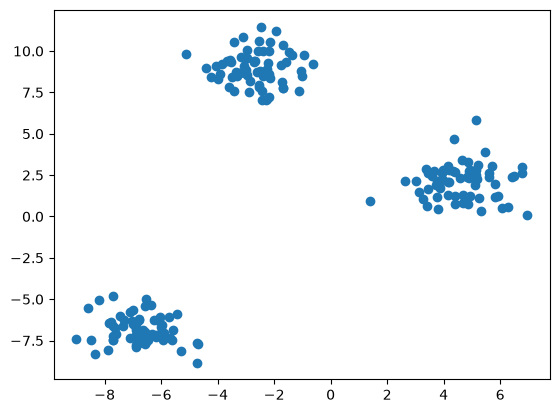

In [40]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])


## **2. 모델링 1**

**Q1. K Means Clustering 비지도 학습 모델을 생성합니다.**

- n_clusters = 2로 먼저 설정해 봅시다.

In [41]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=2)

**Q2. 모델을 학습시킵니다.**

In [42]:
model.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)",

**Q3. centroid의 위치를 데이터 위에 시각화해 봅시다.**

- model.cluster_centers_ : k개의 centroid의 좌표를 확인할 수 있습니다.
- model.labels_ : 각 데이터가 어떤 centroid(label)이 달렸는지를 확인할 수 있습니다.

<Axes: >

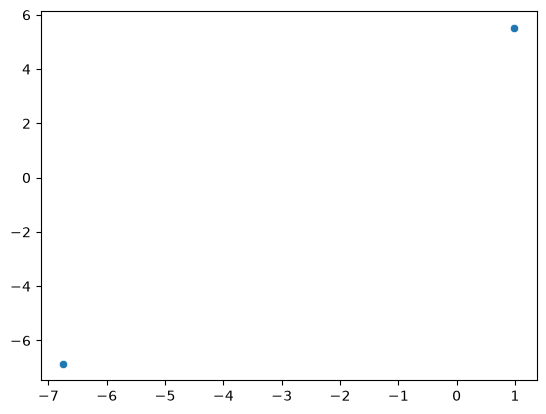

In [43]:
import seaborn as sns

# sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=model.labels_)

sns.scatterplot(
                x=model.cluster_centers_[:, 0],
                y=model.cluster_centers_[:, 1]
)


## **3. 모델링 2**

**Q1. 엘보우 메소드를 활용하여 최적의 K Value를 찾아 봅시다.**

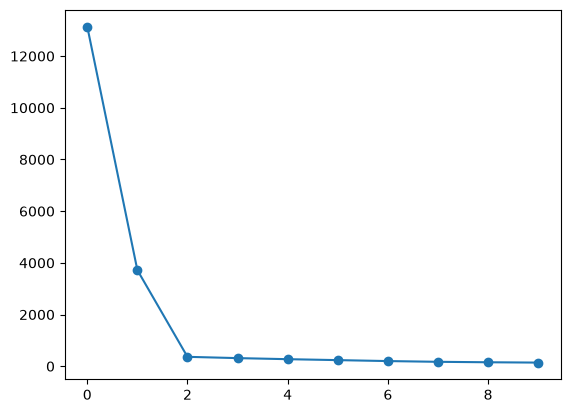

In [44]:
from sklearn.cluster import KMeans

def find_k():
    inertia =[]

    for i in range(1, 11):
        model_km = KMeans(n_clusters=i, random_state=42, n_init=10)
        
        model_km.fit(X)

        inertia.append(model_km.inertia_)

    return inertia

inertia = find_k()

plt.plot(inertia, marker='o')

**Q2. K Means Clustering 비지도 학습 모델을 생성합니다.**

- 엘보우 메소드에서 나온 n_clusters의 개수로 설정합니다.

In [45]:
model_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
model_kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[-2.

**Q3. 데이터의 scatterplot을 그리고, 각 데이터가 어떤 centroid에 분배되었는지를 시각화합니다.**

- model.cluster_centers_ : k개의 centroid의 좌표를 확인할 수 있습니다.
- model.labels_ : 각 데이터가 어떤 centroid(label)이 달렸는지를 확인할 수 있습니다.

<Axes: >

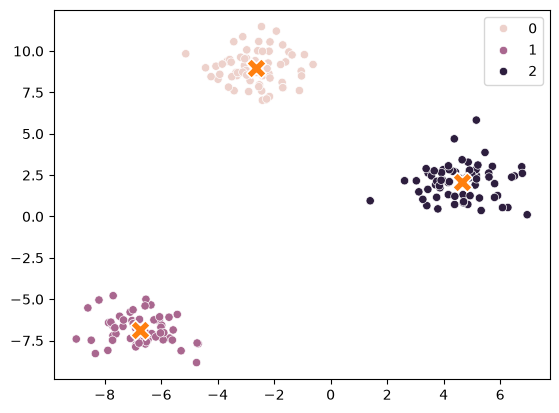

In [49]:
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=model_kmeans.labels_
)

sns.scatterplot(
    x=model_kmeans.cluster_centers_[:, 0],
    y=model_kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)


## **4. 새로운 데이터 예측하기**

**Q1. 새로운 데이터를 입력하고, 해당 데이터가 어떤 그룹에 속하는지를 출력해보고, 시각화해보자.**

In [54]:
import numpy as np

new_data = np.array([[2, 4]])
n_pred = model_kmeans.predict(new_data)

print(n_pred)

[2]


<Axes: >

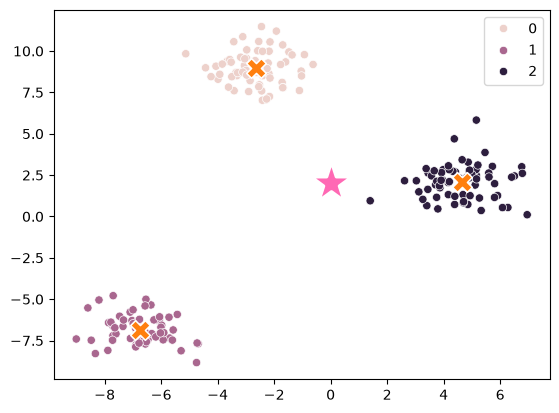

In [63]:
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=model_kmeans.labels_
)

sns.scatterplot(
    x=model_kmeans.cluster_centers_[:, 0],
    y=model_kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)

sns.scatterplot(n_pred, marker='*', s=1000, c='hotpink')

sns.scatterplot()